In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm
from collections import Counter
import math

In [11]:
excel_url = "C:/Users/Next/Downloads/PatientsData.csv"

In [14]:
df = pd.read_csv(
    excel_url,
    sep=";"
    )

last_col = df.columns[-1]
if str(last_col).startswith("Unnamed"):
    df = df.rename(columns={last_col: "Code"})
else:
    df = df.rename(columns={last_col: "Code"})

df = df.drop(columns=["Birthday"])

df = df[df["PET"].str.lower().str.strip() == "yes"]
df = df[df["CT"].str.lower().str.strip() == "yes"]

df = df.dropna(axis=1, how="all")

# coduri_selectate = [2011, 3111, 4111, 5111, 7011, 8011, 9111, 10111, 11111, 12111, 13111, 15011, 16111, 17011, 22011, 23111, 24111, 25111, 26011, 28111, 29111, 30111, 40011, 42111, 43011, 44111]

# df["Code"] = df["Code"].astype(str).str.extract(r"(\d+)").astype(float).astype(int)

# df = df[df["Code"].isin(coduri_selectate)]

# pd.set_option('display.max_rows', None)
# pd.set_option('display.max_columns', None)
# pd.set_option('display.max_colwidth', None)
print(df)

   Gender  Age                      Biopsy positive   CT  PET   Code
0       F   77                     TTF1,NAPSIN A,RP  yes  yes   2011
1       M   75         CK AE1/AE3,CEA,CK7,TTF1,KI67  yes  yes   3111
2       M   68                       TTF1,NAPSIN AM  yes  yes   4111
3       M   63                           P63,CK HMW  yes  yes   5111
4       F   78                                  P63  yes  yes   7011
5       F   66  CK7,TTF1,NAPSIN,CKA1/AE3,SS-CATENIN  yes  yes   8011
6       M   73                  CK AE1/AE3,CK7,CDX2  yes  yes   9111
7       M   73                      P63,TTF1,NAPSIN  yes  yes  10111
8       M   67                            CD56,TTF1  yes  yes  11111
9       M   66                             TTF1,P63  yes  yes  12111
10      M   70                         P63,NECROSIS  yes  yes  13111
11      F   49                      TTF1,NAPSIN,CK7  yes  yes  15011
12      M   79                          CK7,CK5,P63  yes  yes  16111
13      F   50                    

In [15]:
markers = df["Biopsy positive"].dropna()
all_markers = []
for m in markers:
    parts = [x.strip().upper() for x in m.split(",") if x.strip()]
    all_markers.extend(parts)

marker_counts = Counter(all_markers)

marker_df = pd.DataFrame(marker_counts.items(), columns=["Marker", "Nr_of_appearances"])
marker_df = marker_df.sort_values(by="Nr_of_appearances", ascending=False).reset_index(drop=True)

# number of appearances of each marker
print(marker_df)

        Marker  Nr_of_appearances
0         TTF1                 13
1          CK7                 11
2          P63                  7
3       NAPSIN                  6
4     NAPSIN A                  4
5         KI67                  3
6         CDX2                  3
7          P40                  3
8   CK AE1/AE3                  3
9          CK5                  2
10      CK HMW                  1
11   NAPSIN AM                  1
12          RP                  1
13         CEA                  1
14  SS-CATENIN                  1
15    CKA1/AE3                  1
16    NECROSIS                  1
17        CD56                  1


In [16]:
# convert age to numeric value
df["Age"] = pd.to_numeric(df.get("Age", pd.Series(dtype=float)), errors="coerce")

# clean whitespace
def norm_str(x):
    if pd.isna(x):
        return x
    return str(x).strip()

for col in ["Gender", "PET", "CT", "TYPE", "Subtype+ Notes", "Biopsy positive"]:
    if col in df.columns:
        df[col] = df[col].map(norm_str)

In [17]:
def get_patients_codes():
    if "Code" in df.columns:
        df["Code"] = df["Code"].dropna()
    codes = (
        df["Code"]
        .dropna()
        .apply(lambda x: int(float(x)))
        .tolist()
    )
    return codes

In [18]:
patients_codes = get_patients_codes()
print("Patient codes:", patients_codes)

Patient codes: [2011, 3111, 4111, 5111, 7011, 8011, 9111, 10111, 11111, 12111, 13111, 15011, 16111, 22011, 23111, 24111, 25111, 26011, 28111, 29111, 30011, 40011, 42111, 43011, 44111]


C:\Users\Next\AppData\Local\Temp\ipykernel_19888\1025458748.py:18: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap("Greens", len(values))


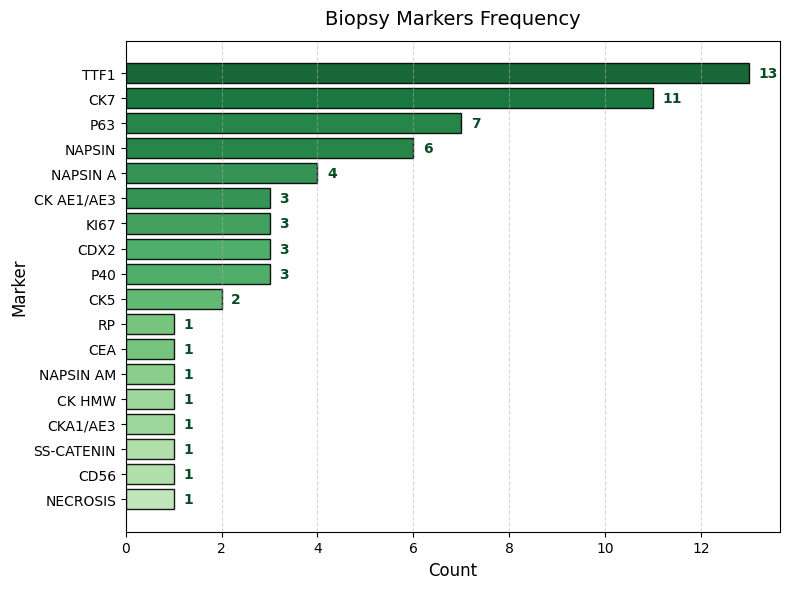

In [19]:
# Biopsy markers frequency 
if "Biopsy positive" in df.columns:
    markers_series = df["Biopsy positive"].dropna()
    all_markers = []
    for entry in markers_series:
        parts = [x.strip().upper() for x in str(entry).split(",") if x.strip()]
        all_markers.extend(parts)

    counter = Counter(all_markers)
    if counter:
        marker_items = sorted(counter.items(), key=lambda kv: kv[1], reverse=True)
        top_n = 20
        labels = [k for k, _ in marker_items[:top_n]]
        values = [v for _, v in marker_items[:top_n]]

        plt.figure(figsize=(8, 6))

        cmap = cm.get_cmap("Greens", len(values))
        colors = [cmap(x) for x in np.linspace(0.9, 0.3, len(values))]

        bars = plt.barh(labels[::-1], values[::-1],
                        color=colors[::-1],
                        edgecolor="black",
                        alpha=0.9)

        for bar, value in zip(bars, values[::-1]):
            plt.text(
                bar.get_width() + 0.2,          
                bar.get_y() + bar.get_height()/2,
                str(value),
                va="center",
                fontsize=10,
                fontweight="bold",
                color="#084c27"
            )

        plt.title("Biopsy Markers Frequency", fontsize=14, pad=12)
        plt.xlabel("Count", fontsize=12)
        plt.ylabel("Marker", fontsize=12)
        plt.grid(axis="x", linestyle="--", alpha=0.5)
        plt.tight_layout()

        plt.show()

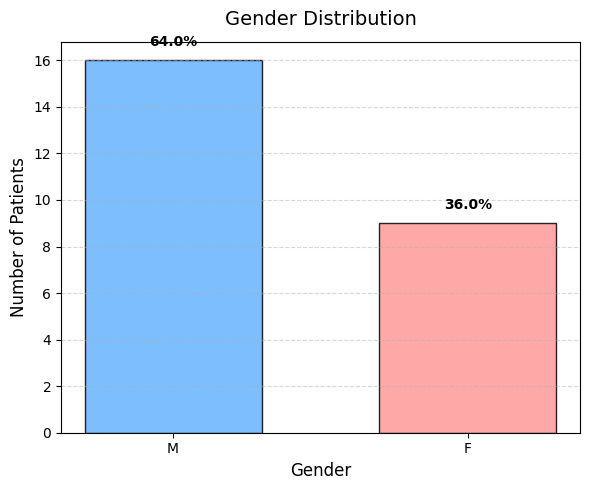

In [22]:
# Gender distribution
if "Gender" in df.columns:
    plt.figure(figsize=(6, 5))
    
    counts = df["Gender"].fillna("Unknown").value_counts()
    total = counts.sum()
    percentages = (counts / total * 100).round(1)
    
    bars = plt.bar(
        counts.index.astype(str),
        counts.values,
        color=["#66b3ff", "#ff9999", "#c2c2f0", "#99ff99"],
        edgecolor="black",
        alpha=0.85,
        width=0.6
    )

    for bar, value, pct in zip(bars, counts.values, percentages):
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.5,
            f"{pct}%",
            ha="center",
            va="bottom",
            fontsize=10,
            fontweight="bold"
        )

    plt.title("Gender Distribution", fontsize=14, pad=12)
    plt.xlabel("Gender", fontsize=12)
    plt.ylabel("Number of Patients", fontsize=12)
    plt.grid(axis="y", linestyle="--", alpha=0.5)
    plt.tight_layout()

    plt.show()

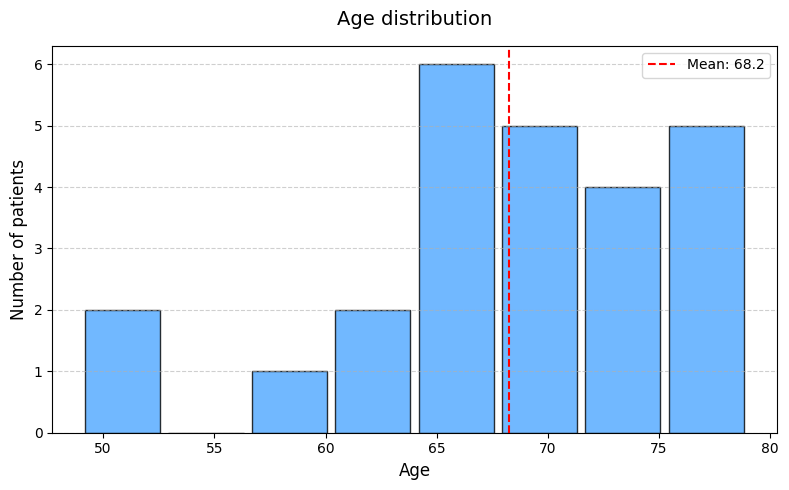

In [23]:
# Age distribution 
if "Age" in df.columns:
    plt.figure(figsize=(8, 5))
    valid_age = df["Age"].dropna()
    bins = max(8, min(25, int(math.sqrt(len(valid_age))))) if len(valid_age) > 0 else 10

    n, bins, patches = plt.hist(
        valid_age,
        bins=bins,
        color="#4da6ff",
        edgecolor="black",
        alpha=0.8,
        rwidth=0.9  
    )

    mean_age = valid_age.mean()
    median_age = valid_age.median()
    plt.axvline(mean_age, color="red", linestyle="dashed", linewidth=1.5, label=f"Mean: {mean_age:.1f}")

    plt.title("Age distribution", fontsize=14, pad=15)
    plt.xlabel("Age", fontsize=12)
    plt.ylabel("Number of patients", fontsize=12)
    plt.grid(axis="y", linestyle="--", alpha=0.6)
    plt.legend()
    plt.tight_layout()
    plt.show()
    


Număr pacienți per categorie:
     Category  Count
    Only TTF1      6
  Only NAPSIN      4
TTF1 + NAPSIN      7
      Neither      8


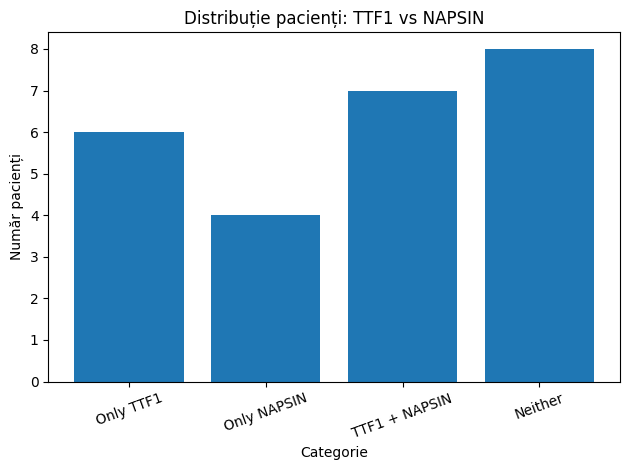

In [ ]:
import re

def parse_markers(value):
    if pd.isna(value):
        return []
    cleaned = re.sub(r"[^\w/ ]+", ",", str(value))
    parts = [p.strip() for p in cleaned.split(",") if p.strip()]
    return parts

MARKER_COL = "Biopsy positive"
if MARKER_COL not in df.columns:
    raise ValueError(f'Coloana cu markerii "{MARKER_COL}" nu există în date.')

df["Markers_list"] = df[MARKER_COL].apply(parse_markers)

def has_ttf1(markers):
    return any("ttf1" in m.lower() for m in markers)

def has_napsin(markers):
    return any("napsin" in m.lower() for m in markers)

df["TTF1"] = df["Markers_list"].apply(has_ttf1)
df["NAPSIN_any"] = df["Markers_list"].apply(has_napsin)

def category(row):
    t, n = row["TTF1"], row["NAPSIN_any"]
    if t and n:
        return "TTF1 + NAPSIN"
    if t and not n:
        return "Only TTF1"
    if n and not t:
        return "Only NAPSIN"
    return "Neither"

df["Category"] = df.apply(category, axis=1)

order = ["Only TTF1", "Only NAPSIN", "TTF1 + NAPSIN", "Neither"]
counts = (df["Category"].value_counts().reindex(order, fill_value=0).reset_index())
counts.columns = ["Category", "Count"]

print("\nNumăr pacienți per categorie:")
print(counts.to_string(index=False))

plt.figure()
plt.bar(counts["Category"], counts["Count"])
plt.title("Distribuție pacienți: TTF1 vs NAPSIN")
plt.xlabel("Categorie")
plt.ylabel("Număr pacienți")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()